# Hydraulic analysis of Koto city

In this notebook you will the different parts of the hydraulic analysis of Koto city, district within Tokyo metropolis.
Data used to calculate and determine hydraulic parameters were gatehered from the following sources:
- Precipitation and other atmospheric data courtesy of the Japan Meteorological Agency (Measuring station: Tokyo Observatory)
- Water level data: Water Information System courtesy of the Ministry of Land, Infrastructure, Transport and Tourism of Japan (Chart datum: Arakawa Peil [A.P.])
- Tidal data: Tide Table Tokyo courtesy of the Japan Meteorological Agency with an average spring tidal range of 187 cm or 1.87 m

In [2]:
#Packages used in this analysis
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats


In [3]:
# #import of atmospheric data 
# import xarray
# filename = 'https://data.gdex.ucar.edu/d640000/kerchunk/anl_isentrop-remote-https.parq'
# ds = xarray.open_dataset(filename, engine='kerchunk')
# ds['bvf2-theta-an-gauss'] # Square of Brunt-Vaisala frequency

In [4]:
# def parse_jp_datetime(year, dt):
#     if pd.isna(dt):
#         return pd.NaT
#     dt = str(dt).replace("年", "").replace("月", "/").replace("日", "").strip()
#     if dt.endswith(" 24:00"):
#         dt = dt.replace(" 24:00", " 00:00")
#         d = pd.to_datetime(f"{year}/{dt}", format="%Y/%m/%d %H:%M", errors="coerce")
#         if pd.notna(d):
#             return d + pd.Timedelta(days=1)
#         return d
#     return pd.to_datetime(f"{year}/{dt}", format="%Y/%m/%d %H:%M", errors="coerce")

In [5]:
# # Read and process hydraulic data for Sumida River (upstream)
# from io import StringIO

# with open("iwabuchi_WL_sumida.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_sumida_up = "\n".join(valid_lines)

# sumida_up = pd.read_csv(
#     StringIO(data_sumida_up),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# sumida_up = sumida_up[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# sumida_up.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                       'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# sumida_up["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_up["year"], sumida_up["date_maxWL"])]

# sumida_up["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_up["year"], sumida_up["date_minWL"])]


In [6]:
# # Read and process hydraulic data for Sumida River (downstream)
# from io import StringIO

# with open("reiganjima_WL_sumida.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_sumida_down = "\n".join(valid_lines)

# sumida_down = pd.read_csv(
#     StringIO(data_sumida_down),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# sumida_down = sumida_down[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# sumida_down.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                        'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# sumida_down["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_down["year"], sumida_down["date_maxWL"])]

# sumida_down["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(sumida_down["year"], sumida_down["date_minWL"])]




In [7]:
# # Read and process hydraulic data for Arakawa River (upstream)
# from io import StringIO

# with open("nanbata_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_arakawa_up = "\n".join(valid_lines)

# arakawa_up = pd.read_csv(
#     StringIO(data_arakawa_up),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# arakawa_up = arakawa_up[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# arakawa_up.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                       'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# arakawa_up["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_up["year"], arakawa_up["date_maxWL"])]

# arakawa_up["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_up["year"], arakawa_up["date_minWL"])]

In [8]:
# # Read and process hydraulic data for Arakawa River (midstream)
# from io import StringIO

# with open("nishiarai_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_arakawa_mid = "\n".join(valid_lines)

# arakawa_mid = pd.read_csv(
#     StringIO(data_arakawa_mid),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])


# # Select relevant columns and rename
# arakawa_mid = arakawa_mid[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# arakawa_mid.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                        'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# arakawa_mid["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_mid["year"], arakawa_mid["date_maxWL"])]

# arakawa_mid["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_mid["year"], arakawa_mid["date_minWL"])]


In [9]:
# # Read and process hydraulic data for Arakawa River (downstream)
# from io import StringIO

# with open("onagigawa_WL_arakawa.dat", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_arakawa_down = "\n".join(valid_lines)

# arakawa_down = pd.read_csv(
#     StringIO(data_arakawa_down),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# arakawa_down = arakawa_down[[0, 1, 3, 4, 6, 8, 10, 12, 14, 15]]
# arakawa_down.columns = ['year', 'maxWL', 'date_maxWL', 'wetmeanWL+STD', 'wetmeanWL',
#                         'wetmeanWL-STD', 'drymeanWL', 'minWL', 'date_minWL','meanWL']

# # Clean and convert date columns to datetime format
# arakawa_down["date_maxWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_down["year"], arakawa_down["date_maxWL"])]

# arakawa_down["date_minWL"] = [parse_jp_datetime(y, d)
#     for y, d in zip(arakawa_down["year"], arakawa_down["date_minWL"])]


In [10]:
# #Saving dataframes to CSV files
# sumida_up.to_csv('sumida_upstream_iwabuchi.csv', index=False)
# sumida_down.to_csv('sumida_downstream_reiganjima.csv', index=False)
# arakawa_up.to_csv('arakawa_upstream_nanbata.csv', index=False)
# arakawa_mid.to_csv('arakawa_midstream_nishiarai.csv', index=False)
# arakawa_down.to_csv('arakawa_downstream_onagigawa.csv', index=False)

In [11]:
# # Read and process hydraulic data for Tokyo (1872-1906)
# from io import StringIO

# with open("1872-1906.csv", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_1872_1906 = "\n".join(valid_lines)

# tokyo_P_1872_1906 = pd.read_csv(
#     StringIO(data_1872_1906),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])


# # Select relevant columns and rename
# tokyo_P_1872_1906 = tokyo_P_1872_1906[[0, 1, 5]]
# tokyo_P_1872_1906.columns = ['date', 'daily_total', 'hourly_max']

# # Convert date column to datetime format
# tokyo_P_1872_1906["date"] = pd.to_datetime(tokyo_P_1872_1906["date"].astype(str).str.strip(),
#                                             format="%Y/%m/%d", errors="coerce")


In [12]:
# #Read and process hydraulic data for Tokyo (1907-1966)
# from io import StringIO

# with open("1907-1966.csv", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_1907_1966 = "\n".join(valid_lines)

# tokyo_P_1907_1966 = pd.read_csv(
#     StringIO(data_1907_1966),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])


# # Select relevant columns and rename
# tokyo_P_1907_1966 = tokyo_P_1907_1966[[0, 1, 5]]
# tokyo_P_1907_1966.columns = ['date', 'daily_total', 'hourly_max']

# # Convert date column to datetime format
# tokyo_P_1907_1966["date"] = pd.to_datetime(tokyo_P_1907_1966["date"].astype(str).str.strip(),
#                                             format="%Y/%m/%d", errors="coerce")


In [13]:
# # Read and process hydraulic data for Tokyo (1967-2026)
# from io import StringIO

# with open("1967-2026.csv", "r", encoding="cp932", errors="replace") as f:
#     lines = f.readlines()

# valid_lines = []
# for line in lines:
#     s = line.strip()
#     if not s or s.startswith("#"):
#         continue
#     if s[:4].isdigit() and "," in s:
#         valid_lines.append(s)

# data_1967_2026 = "\n".join(valid_lines)

# tokyo_P_1967_2026 = pd.read_csv(
#     StringIO(data_1967_2026),
#     sep=",",
#     header=None,
#     engine="python",
#     on_bad_lines="skip",
#     na_values=["-9999.00", "$", "-", "", "0.00"])

# # Select relevant columns and rename
# tokyo_P_1967_2026 = tokyo_P_1967_2026[[0, 1, 5]]
# tokyo_P_1967_2026.columns = ['date', 'daily_total', 'hourly_max']

# # Convert date column to datetime format
# tokyo_P_1967_2026["date"] = pd.to_datetime(tokyo_P_1967_2026["date"].astype(str).str.strip(),
#                                             format="%Y/%m/%d", errors="coerce")

In [14]:
# #Combine all Tokyo datasets into a single DataFrame and save to csv
# tokyo_P_all = pd.concat([tokyo_P_1872_1906, tokyo_P_1907_1966, tokyo_P_1967_2026], ignore_index=True)
# Tokyo_P_daily = tokyo_P_all[["date", "daily_total", "hourly_max"]]
# Tokyo_P_daily.to_csv('Tokyo_P_daily.csv', index=False)

In [15]:
#Load csv files into dataframes
sumida_up = pd.read_csv('sumida_upstream_iwabuchi.csv')
sumida_down = pd.read_csv('sumida_downstream_reiganjima.csv')
arakawa_up = pd.read_csv('arakawa_upstream_nanbata.csv')
arakawa_mid = pd.read_csv('arakawa_midstream_nishiarai.csv')
arakawa_down = pd.read_csv('arakawa_downstream_onagigawa.csv')

In [16]:
#Removing rows with NaN values in the 'maxWL' column
sumida_up = sumida_up.dropna(subset=['maxWL'])
sumida_down = sumida_down.dropna(subset=['maxWL'])
arakawa_up = arakawa_up.dropna(subset=['maxWL'])
arakawa_mid = arakawa_mid.dropna(subset=['maxWL'])
arakawa_down = arakawa_down.dropna(subset=['maxWL'])

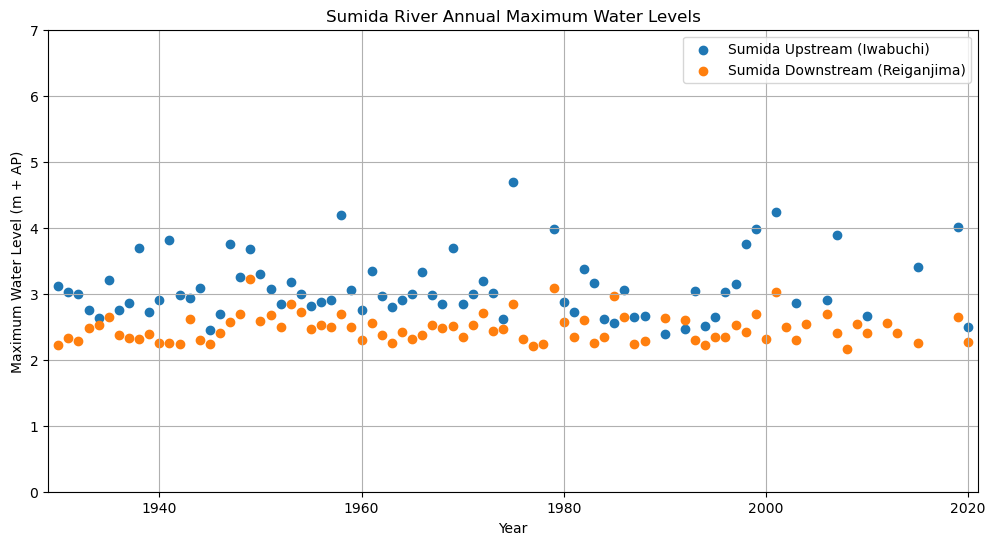

In [17]:
#Sumida river water level analysis
plt.figure(figsize=(12, 6))
plt.scatter(sumida_up['year'], sumida_up['maxWL'], label='Sumida Upstream (Iwabuchi)')
plt.scatter(sumida_down['year'], sumida_down['maxWL'], label='Sumida Downstream (Reiganjima)')
plt.title('Sumida River Annual Maximum Water Levels')
plt.xlabel('Year')
plt.ylabel('Maximum Water Level (m + AP)')
plt.xlim(sumida_down['year'].min()-1, sumida_up['year'].max()+1)
plt.ylim(0, 7)
plt.grid()
plt.legend()
plt.show()

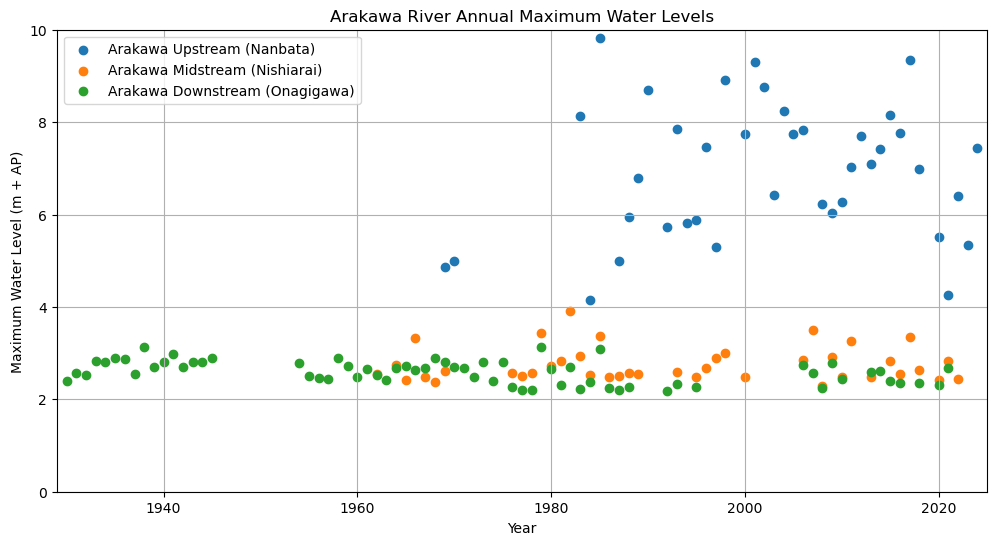

In [18]:
#Arakawa river water level analysis
plt.figure(figsize=(12, 6))
plt.scatter(arakawa_up['year'], arakawa_up['maxWL'], label='Arakawa Upstream (Nanbata)')
plt.scatter(arakawa_mid['year'], arakawa_mid['maxWL'], label='Arakawa Midstream (Nishiarai)')
plt.scatter(arakawa_down['year'], arakawa_down['maxWL'], label='Arakawa Downstream (Onagigawa)')
plt.title('Arakawa River Annual Maximum Water Levels')
plt.xlabel('Year')
plt.ylabel('Maximum Water Level (m + AP)')
plt.xlim(arakawa_down['year'].min()-1, arakawa_up['year'].max()+1)
plt.ylim(0, 10)
plt.grid()
plt.legend()
plt.show()

In [36]:
def ecdf(data):
    """Compute the empirical cumulative distribution function (ECDF) for a one-dimensional array of measurements."""
    n = len(data)
    x = np.sort(data)
    y = np.arange(1, n + 1) / n
    return x, y

In [19]:
# Load monthly total precipitation data for analysis
P_tokyo = pd.read_csv('monthly_total_P_tokyo.csv', delimiter=';', encoding='utf-8')

dict_months = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
               7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
mean_permonth = np.array([])
for month, name in dict_months.items():
    mean_permonth = np.append(mean_permonth, P_tokyo[name].mean())
total_annual_mean_prcp = P_tokyo['Annual'].mean()

# print(mean_permonth)
# print(total_annual_mean_prcp)

In [20]:
#Load Tokyo daily precipitation data and plot daily total and hourly max precipitation
Tokyo_P_daily = pd.read_csv('Tokyo_P_daily.csv')

#Drop NaN values from the daily total and hourly max precipitation columns
Tokyo_P_daily = Tokyo_P_daily.dropna(subset=['daily_total', 'hourly_max'])



Text(0.5, 1.0, 'Tokyo Daily Precipitation (1872-2026)')

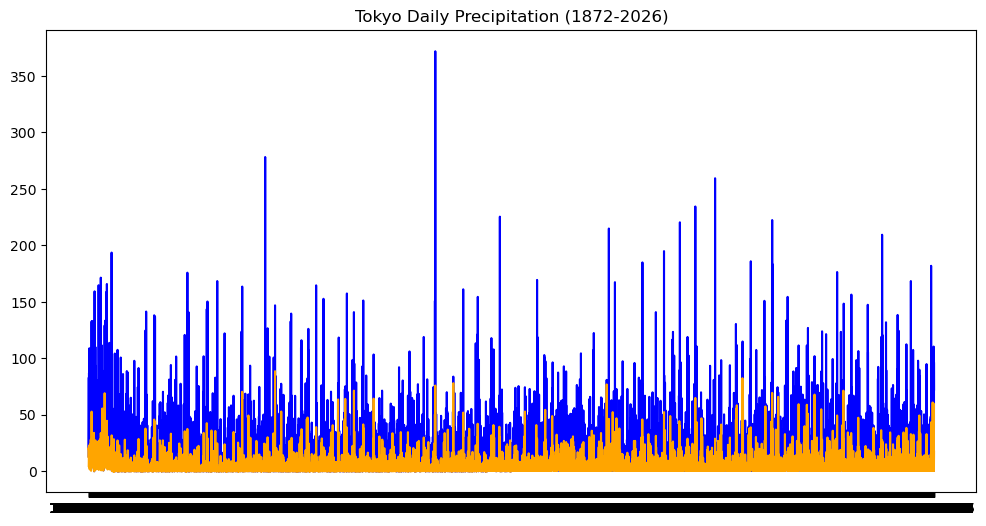

In [21]:
#plot daily total and hourly max precipitation
plt.figure(figsize=(12, 6))
plt.plot(Tokyo_P_daily['date'], Tokyo_P_daily['daily_total'], label='Daily Total Precipitation (mm)', color='blue')
plt.plot(Tokyo_P_daily['date'], Tokyo_P_daily['hourly_max'], label='Hourly Max Precipitation (mm)', color='orange')
plt.title('Tokyo Daily Precipitation (1872-2026)')

In [39]:
#Sampling the daily precipitation data for yearly maxima 
Tokyo_P_daily['year'] = Tokyo_P_daily['date'].str[:4].astype(int)
Tokyo_P_yearly_idxmax = Tokyo_P_daily.groupby('year')['daily_total'].idxmax()
Tokyo_P_yearly_max = Tokyo_P_daily.loc[Tokyo_P_yearly_idxmax]

#Fit to Generalized Extreme Value (GEV) distribution
params_ym_Tokyo = stats.genextreme.fit(Tokyo_P_yearly_max['daily_total'].dropna())

x_gev_daily = np.linspace(ecdf(Tokyo_P_yearly_max['daily_total'].dropna())[0].min(), ecdf(Tokyo_P_yearly_max['daily_total'].dropna())[0].max(), 100)
cdf_gev_daily = stats.genextreme.cdf(x_gev_daily, *params_ym_Tokyo)

In [54]:
#Resample the daily precipitation data for a rolling 72-hour sum and calculate the maximum for each year
#Copy the Tokyo_P_daily DataFrame to avoid modifying the original data
daily = Tokyo_P_daily.copy()

daily["date"] = pd.to_datetime(daily["date"].astype(str).str.strip(), errors="coerce")
# daily.head()
daily["daily_total"] = pd.to_numeric(daily["daily_total"], errors="coerce")

daily = (daily.dropna(subset=["date", "daily_total"]).sort_values("date")
         .drop_duplicates("date").set_index("date"))


# daily["date"] = pd.to_datetime(daily["date"].astype(str).str.strip(), errors="coerce")

#Check for missing dates
full_dates = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing_dates = full_dates.difference(daily.index)

#Calculate the rolling 72-hour sum of daily precipitation
daily["precip_72h"] = (daily["daily_total"].rolling(window=3, min_periods=3).sum())

#Extract the maximum 72-hour precipitation for each year
annual_72h_max = (daily["precip_72h"].groupby(daily.index.year).max().dropna())

In [56]:
#Fit the annual 72-hour maximum precipitation to a GEV distribution
params_72h_Tokyo = stats.genextreme.fit(annual_72h_max.dropna())

#Calculate precipitation for different return periods using the GEV distribution
return_periods = [2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]
precipitation_return_periods = {}
for i, T in enumerate(return_periods):
    p = 1 - 1/T
    precipitation_return_periods[T] = stats.genextreme.ppf(p, *params_72h_Tokyo)
    print(f"Return period:{T} years, 72-hour Precipitation: {precipitation_return_periods[T]:.2f} mm")

Return period:2 years, 72-hour Precipitation: 174.96 mm
Return period:5 years, 72-hour Precipitation: 233.67 mm
Return period:10 years, 72-hour Precipitation: 272.75 mm
Return period:20 years, 72-hour Precipitation: 310.39 mm
Return period:50 years, 72-hour Precipitation: 359.35 mm
Return period:100 years, 72-hour Precipitation: 396.21 mm
Return period:200 years, 72-hour Precipitation: 433.08 mm
Return period:500 years, 72-hour Precipitation: 481.94 mm
Return period:1000 years, 72-hour Precipitation: 519.05 mm
Return period:2000 years, 72-hour Precipitation: 556.28 mm
Return period:5000 years, 72-hour Precipitation: 605.72 mm
Return period:10000 years, 72-hour Precipitation: 643.29 mm


In [ ]:
#Calculate precipitation for different return periods using the GEV distribution
return_periods = [2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]
precipitation_return_periods = {}

for i, T in enumerate(return_periods):
    p = 1 - 1/T
    precipitation_return_periods[T] = stats.genextreme.ppf(p, *params_ym_Tokyo)
    print(f"Return period:{T} years, Daily Precipitation: {precipitation_return_periods[T]:.2f} mm")

Return period: 2 years, Precipitation: 110.37 mm
Return period: 5 years, Precipitation: 155.85 mm
Return period: 10 years, Precipitation: 186.21 mm
Return period: 20 years, Precipitation: 215.51 mm
Return period: 50 years, Precipitation: 253.69 mm
Return period: 100 years, Precipitation: 282.51 mm
Return period: 200 years, Precipitation: 311.38 mm
Return period: 500 years, Precipitation: 349.74 mm
Return period: 1000 years, Precipitation: 378.93 mm
Return period: 2000 years, Precipitation: 408.28 mm
Return period: 5000 years, Precipitation: 447.33 mm
Return period: 10000 years, Precipitation: 477.07 mm


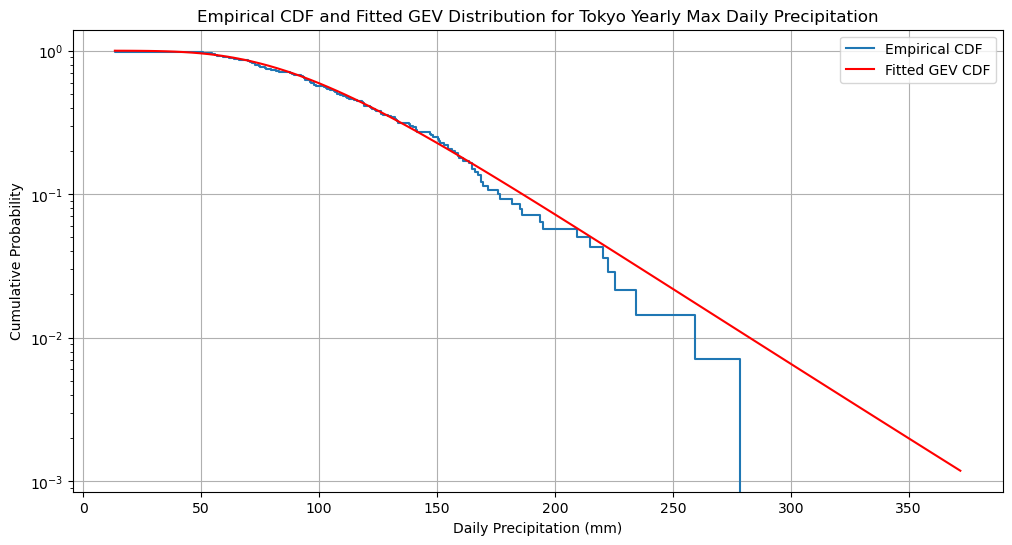

In [42]:
#Plotting the empirical cumulative distribution function (ECDF) and the fitted GEV distribution
plt.figure(figsize=(12, 6))
plt.step(ecdf(Tokyo_P_yearly_max['daily_total'].dropna())[0], 1 - ecdf(Tokyo_P_yearly_max['daily_total'].dropna())[1], label='Empirical CDF')
plt.plot(x_gev_daily, 1- cdf_gev_daily, label='Fitted GEV CDF', color='red')
plt.title('Empirical CDF and Fitted GEV Distribution for Tokyo Yearly Max Daily Precipitation')
plt.xlabel('Daily Precipitation (mm)')
plt.ylabel('Cumulative Probability')
plt.yscale('log')
plt.grid()
plt.legend()
plt.show()

In [22]:
#Restructure into new dataframe with three columns: date, precipitation and annual_p
P_monthly = pd.DataFrame({"date": pd.date_range(start='1875-01-01', end='2025-12-31', freq='ME'),
    "precipitation": P_tokyo[["Jan", "Feb", "Mar", "Apr", "May", "Jun",
         "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]].to_numpy().flatten()})

P_monthly = P_monthly.iloc[5:].reset_index(drop=True)  # Reset index after slicing to remove missing values at the beginning of the dataset

# wet_year_total = P_monthly.groupby(P_monthly['date'].dt.year)['precipitation'].sum().reset_index() # from october to september rolling average


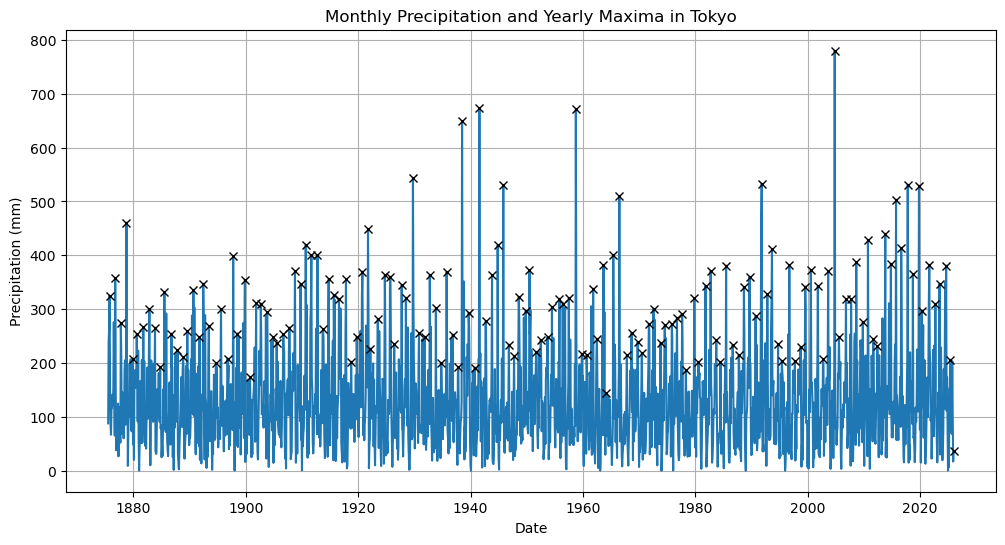

In [23]:
# #Sampling for yearly precipitation maxima
P_monthly['year'] = P_monthly['date'].dt.isocalendar().year
P_monthly_idxmax = P_monthly.groupby('year')['precipitation'].idxmax()
P_monthly_yearly_max = P_monthly.loc[P_monthly_idxmax].reset_index(drop=True)


plt.figure(figsize=(12, 6))
plt.plot(P_monthly['date'], P_monthly['precipitation'], label='Monthly Precipitation')
plt.plot(P_monthly_yearly_max['date'], P_monthly_yearly_max['precipitation'], 'kx', label='Yearly Maxima')
plt.title('Monthly Precipitation and Yearly Maxima in Tokyo')
plt.xlabel('Date')
plt.ylabel('Precipitation (mm)')
plt.grid()
plt.show()


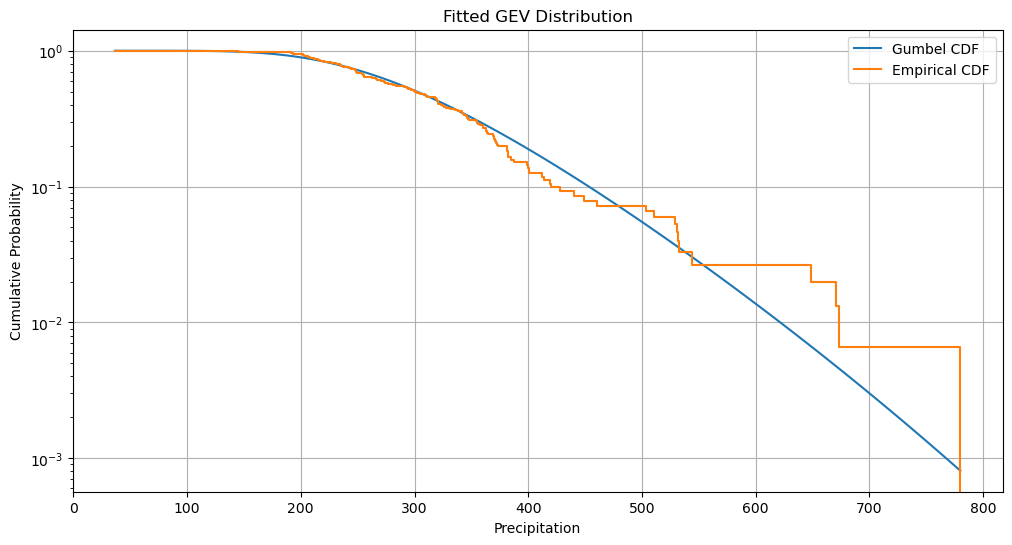

In [25]:
#Fit GEV distribution to the yearly maxima of precipitation
params_ym = stats.genextreme.fit(P_monthly_yearly_max['precipitation'])

x_gev = np.linspace(min(ecdf(P_monthly_yearly_max['precipitation'])[0]), max(ecdf(P_monthly_yearly_max['precipitation'])[0]), 100)
cdf_gev = stats.genextreme.cdf(x_gev, *params_ym)


plt.figure(figsize=(12, 6))
plt.plot(x_gev, 1-cdf_gev, label='Gumbel CDF')
plt.step(ecdf(P_monthly_yearly_max['precipitation'])[0], 1 - ecdf(P_monthly_yearly_max['precipitation'])[1], label='Empirical CDF', where='post')
plt.xlabel('Precipitation')
plt.ylabel('Cumulative Probability')
plt.title('Fitted GEV Distribution')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

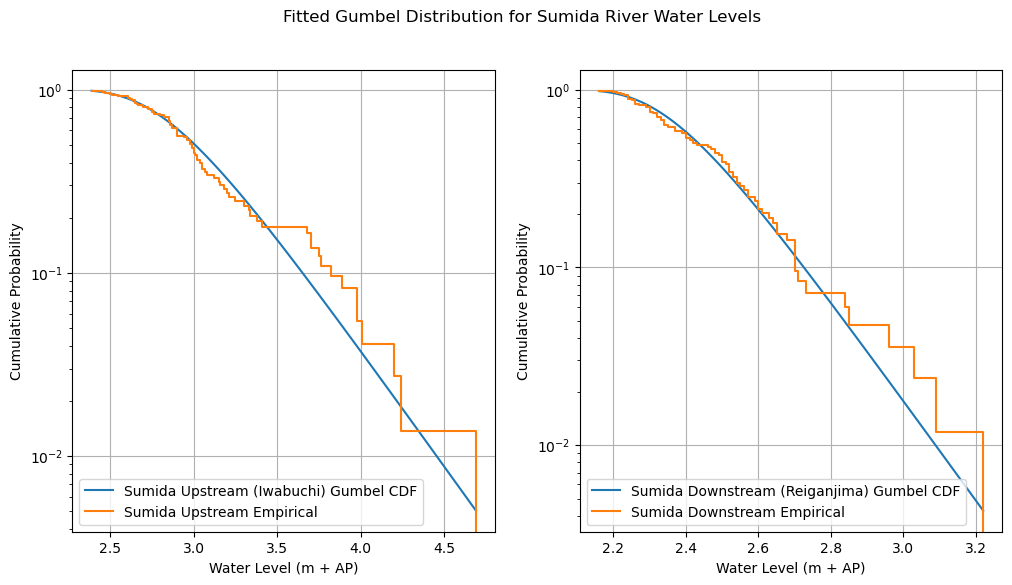

In [26]:
#Fit Gumbel distribution to yearly maxima of water levels for the Sumida river
params_sumida_up = stats.gumbel_r.fit(sumida_up['maxWL'])
params_sumida_down = stats.gumbel_r.fit(sumida_down['maxWL'])

x_sumida_up = np.linspace(min(ecdf(sumida_up['maxWL'])[0]), max(ecdf(sumida_up['maxWL'])[0]), 100)
x_sumida_down = np.linspace(min(ecdf(sumida_down['maxWL'])[0]), max(ecdf(sumida_down['maxWL'])[0]), 100)
cdf_sumida_up = stats.gumbel_r.cdf(x_sumida_up, *params_sumida_up)
cdf_sumida_down = stats.gumbel_r.cdf(x_sumida_down, *params_sumida_down)

fig, axes = plt.subplots(1,2, figsize=(12, 6))
axes[0].plot(x_sumida_up, 1-cdf_sumida_up, label='Sumida Upstream (Iwabuchi) Gumbel CDF')
axes[1].plot(x_sumida_down, 1-cdf_sumida_down, label='Sumida Downstream (Reiganjima) Gumbel CDF')
axes[0].step(ecdf(sumida_up['maxWL'])[0], 1 - ecdf(sumida_up['maxWL'])[1], label='Sumida Upstream Empirical', where='post')
axes[1].step(ecdf(sumida_down['maxWL'])[0], 1 - ecdf(sumida_down['maxWL'])[1], label='Sumida Downstream Empirical', where='post')
axes[0].set_xlabel('Water Level (m + AP)')
axes[0].set_ylabel('Cumulative Probability')
axes[1].set_xlabel('Water Level (m + AP)')
axes[1].set_ylabel('Cumulative Probability')
plt.suptitle('Fitted Gumbel Distribution for Sumida River Water Levels')
axes[0].set_yscale('log')
axes[1].set_yscale('log')
axes[0].legend()
axes[1].legend()
axes[0].grid(True)
axes[1].grid(True)
plt.show()

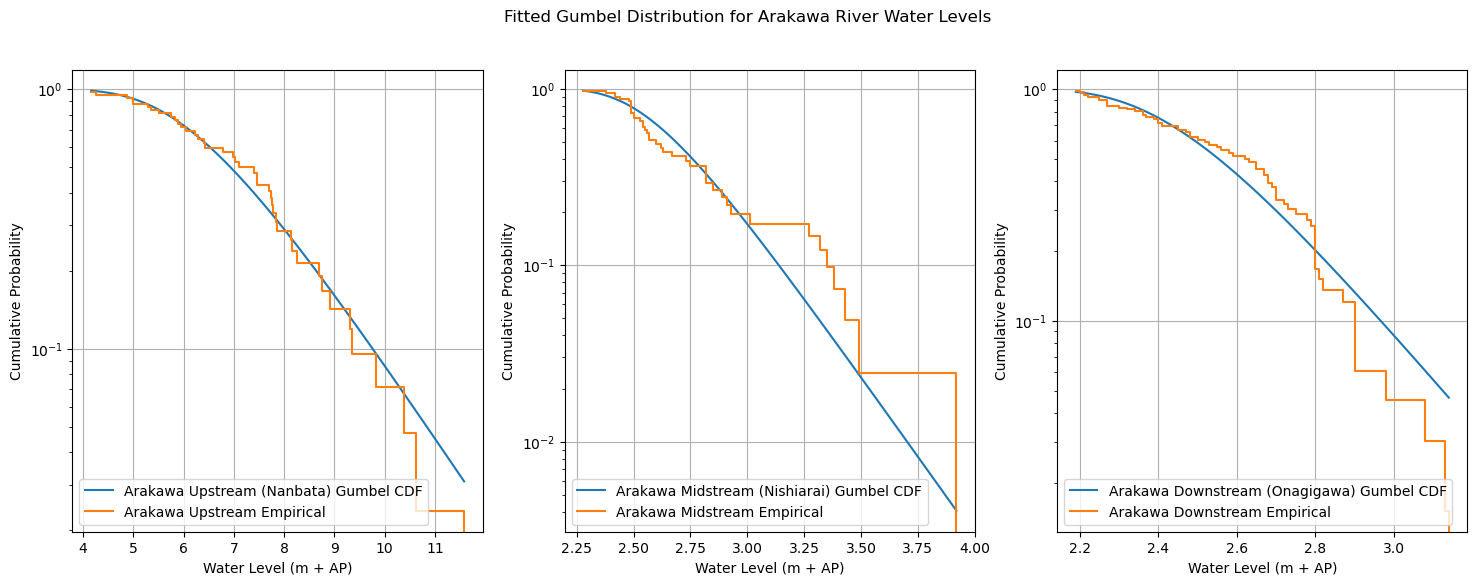

In [27]:
#Fit Gumbel distribution to yearly maxima of water levels for the Arakawa river
params_arakawa_up = stats.gumbel_r.fit(arakawa_up['maxWL'])
params_arakawa_mid = stats.gumbel_r.fit(arakawa_mid['maxWL'])
params_arakawa_down = stats.gumbel_r.fit(arakawa_down['maxWL'])

x_arakawa_up = np.linspace(min(ecdf(arakawa_up['maxWL'])[0]), max(ecdf(arakawa_up['maxWL'])[0]), 100)
x_arakawa_mid = np.linspace(min(ecdf(arakawa_mid['maxWL'])[0]), max(ecdf(arakawa_mid['maxWL'])[0]), 100)
x_arakawa_down = np.linspace(min(ecdf(arakawa_down['maxWL'])[0]), max(ecdf(arakawa_down['maxWL'])[0]), 100)
cdf_arakawa_up = stats.gumbel_r.cdf(x_arakawa_up, *params_arakawa_up)
cdf_arakawa_mid = stats.gumbel_r.cdf(x_arakawa_mid, *params_arakawa_mid)
cdf_arakawa_down = stats.gumbel_r.cdf(x_arakawa_down, *params_arakawa_down)


fig, axes = plt.subplots(1,3, figsize=(18, 6))
axes[0].plot(x_arakawa_up, 1-cdf_arakawa_up, label='Arakawa Upstream (Nanbata) Gumbel CDF')
axes[1].plot(x_arakawa_mid, 1-cdf_arakawa_mid, label='Arakawa Midstream (Nishiarai) Gumbel CDF')
axes[2].plot(x_arakawa_down, 1-cdf_arakawa_down, label='Arakawa Downstream (Onagigawa) Gumbel CDF')
axes[0].step(ecdf(arakawa_up['maxWL'])[0], 1 - ecdf(arakawa_up['maxWL'])[1], label='Arakawa Upstream Empirical', where='post')
axes[1].step(ecdf(arakawa_mid['maxWL'])[0], 1 - ecdf(arakawa_mid['maxWL'])[1], label='Arakawa Midstream Empirical', where='post')
axes[2].step(ecdf(arakawa_down['maxWL'])[0], 1 - ecdf(arakawa_down['maxWL'])[1], label='Arakawa Downstream Empirical', where='post')
axes[0].set_xlabel('Water Level (m + AP)')
axes[0].set_ylabel('Cumulative Probability')
axes[1].set_xlabel('Water Level (m + AP)')
axes[1].set_ylabel('Cumulative Probability')
axes[2].set_xlabel('Water Level (m + AP)')
axes[2].set_ylabel('Cumulative Probability')
plt.suptitle('Fitted Gumbel Distribution for Arakawa River Water Levels')
axes[0].set_yscale('log')
axes[1].set_yscale('log')
axes[2].set_yscale('log')
axes[0].legend()
axes[1].legend()
axes[2].legend()
axes[0].grid(True)
axes[1].grid(True)
axes[2].grid(True)
plt.show()


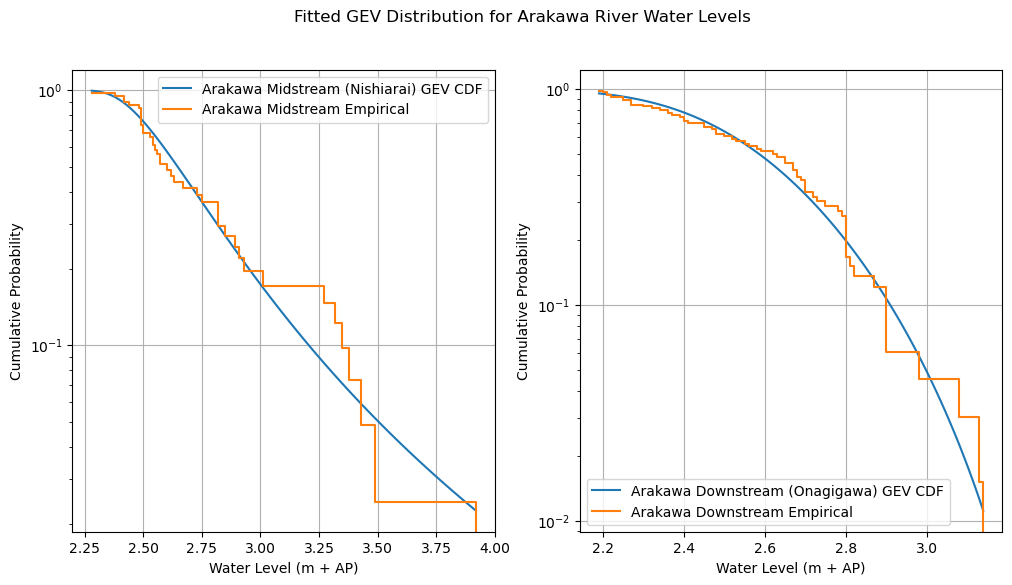

In [28]:
#Fit GEV to Arakawa mid and downstream water levels
params_arakawa_mid_gev = stats.genextreme.fit(arakawa_mid['maxWL'])
params_arakawa_down_gev = stats.genextreme.fit(arakawa_down['maxWL'])

cdf_arakawa_mid_gev = stats.genextreme.cdf(x_arakawa_mid, *params_arakawa_mid_gev)
cdf_arakawa_down_gev = stats.genextreme.cdf(x_arakawa_down, *params_arakawa_down_gev)

fig,axes = plt.subplots(1,2, figsize=(12, 6))
axes[0].plot(x_arakawa_mid, 1-cdf_arakawa_mid_gev, label='Arakawa Midstream (Nishiarai) GEV CDF')
axes[1].plot(x_arakawa_down, 1-cdf_arakawa_down_gev, label='Arakawa Downstream (Onagigawa) GEV CDF')
axes[0].step(ecdf(arakawa_mid['maxWL'])[0], 1 - ecdf(arakawa_mid['maxWL'])[1], label='Arakawa Midstream Empirical', where='post')
axes[1].step(ecdf(arakawa_down['maxWL'])[0], 1 - ecdf(arakawa_down['maxWL'])[1], label='Arakawa Downstream Empirical', where='post')
axes[0].set_xlabel('Water Level (m + AP)')
axes[0].set_ylabel('Cumulative Probability')
axes[1].set_xlabel('Water Level (m + AP)')
axes[1].set_ylabel('Cumulative Probability')
plt.suptitle('Fitted GEV Distribution for Arakawa River Water Levels')
axes[0].set_yscale('log')
axes[1].set_yscale('log')
axes[0].legend()
axes[1].legend()
axes[0].grid(True)
axes[1].grid(True)
plt.show()


In [29]:
print(P_monthly[P_monthly['date'].dt.year == 2016])


           date  precipitation  year
1687 2016-01-31           85.0  2016
1688 2016-02-29           57.0  2016
1689 2016-03-31          103.0  2016
1690 2016-04-30          120.0  2016
1691 2016-05-31          137.5  2016
1692 2016-06-30          174.5  2016
1693 2016-07-31           81.5  2016
1694 2016-08-31          414.0  2016
1695 2016-09-30          287.0  2016
1696 2016-10-31           96.5  2016
1697 2016-11-30          139.0  2016
1698 2016-12-31           84.0  2016


In [30]:
#Rainfall levels for august 2007,2011,2016; september 2014; october 2009; december 2010
august_P = P_monthly[(P_monthly['date'].dt.month == 8) & (P_monthly['date'].dt.year.isin([2007, 2011, 2016]))]['precipitation']
september_P = P_monthly[(P_monthly['date'].dt.month == 9) & (P_monthly['date'].dt.year.isin([2014]))]['precipitation']
october_P = P_monthly[(P_monthly['date'].dt.month == 10) & (P_monthly['date'].dt.year.isin([2009]))]['precipitation']
december_P = P_monthly[(P_monthly['date'].dt.month == 12) & (P_monthly['date'].dt.year.isin([2010]))]['precipitation']

print("Rainfall levels for August 2007, 2011, 2016:", august_P.values)
print("Rainfall level for September 2014:", september_P.values)
print("Rainfall level for October 2009:", october_P.values)
print("Rainfall level for December 2010:", december_P.values)

Rainfall levels for August 2007, 2011, 2016: [  9.5 244.  414. ]
Rainfall level for September 2014: [155.5]
Rainfall level for October 2009: [276.5]
Rainfall level for December 2010: [145.5]


In [31]:
#Calculation rainfall with a return period of 1000 years
return_period = 280
# Calculate the cumulative probability for the return period
cumulative_probability = 1 - (1 / return_period)

rainfall_1000yr = stats.genextreme.ppf(cumulative_probability, *params_ym)

print(f"Estimated rainfall for a return period of {return_period} years: {rainfall_1000yr:.2f} mm")


#Return period corresponding to a 


Estimated rainfall for a return period of 280 years: 689.19 mm
